# Epiphyte lysimeter: field analysis

Reproduces the report *Epiphyte lysimeter: first field results* from the raw logger files: calibration, alignment with the weather and fog data, storm events, water balance, fog, evaporation and data-quality checks.

**How to run**
1. Put the four CSVs (`lys2.csv`, `tempest.csv`, `fog_AF_15min.csv`, `loggers.csv`) in the same folder as this notebook, or point `DATA_DIR` at them.
2. Run all cells (*Kernel → Restart & Run All*). Needs `pandas`, `numpy` and `matplotlib`.
3. Figures (PNG) and processed tables (CSV) are written to `lysimeter_outputs/`.

When new data arrives, just replace the CSVs and rerun. Storm events, fog windows and rain-free drying windows are detected automatically (the rules are in the configuration cell), and the tip counter is corrected wherever the logger resets. The interpretation notes in the text cells describe the 16–22 Oct 2026 record; the printed numbers update with the data.

In [16]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, Markdown

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

def rnd(df, n=2):
    # Round numeric columns only (datetime columns stay as they are)
    return df.round({c: n for c in df.select_dtypes(include=["float", "integer"]).columns})

# Chart colours: one accent for what a chart is about, greys for context
ACCENT = "#2a78d6"       # lysimeter weight; drainage + storage
WARM = "#eb6834"         # temperature
DRAIN = "#1baf7a"        # drainage tips
RAIN = "#6250d6"         # Tempest rain
FOG = "#e87ba4"          # modelled fog (FIESTA)
HUMID = "#008300"        # relative humidity
MUTED = "#a3a199"        # rain, tips, measured input
MUTED_LIGHT = "#d6d4cc"  # fog rug, reference series
TEXT = "#0b0b0b"
TEXT2 = "#52514e"
GRID = "#e8e7e2"
REF = "#7a7974"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": REF, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": TEXT,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})

## Configuration

All site-specific numbers live here. The calibration follows

$$W = \frac{(\mathrm{ADC} - \mathrm{ADC}_0 - \alpha\,\Delta T)\,S}{1 + \beta\,\Delta T}, \qquad \Delta T = T - T_{ref}$$

and the water-balance terms are expressed in mm over the epiphyte's projected area $A$:

$$ET = P_{epi} - D_{epi} - \Delta S, \qquad P_{epi} = TF + F, \qquad \Delta S = \frac{10\,\Delta W}{A}, \qquad F = F_{model}\,\frac{A_{fog}}{A}$$

The drainage funnel ($A_{funnel}$ = 314 cm²) is larger than the epiphyte and also catches water that never passed through it. Each tip ($V_{tip}$ = 0.2 mm × $A_{funnel}$ = 6.28 mL) is therefore attributed to the epiphyte in proportion to its vertical projection over the funnel:

$$D_{epi} = \frac{10\,n_{tip}\,V_{tip}}{A}\cdot\frac{A}{A_{funnel}} = n_{tip} \times 0.2\ \mathrm{mm}$$

so each tip carries 5.43 mL from the epiphyte, which is 0.2 mm over its projected area.

The event, fog and drying windows were picked by hand from the 16–21 Oct record. Edit or extend them as new data comes in.

In [17]:
# ---------- Files ----------
DATA_DIR = Path(".")                 # folder that holds the four CSVs
OUT_DIR = Path("lysimeter_outputs")  # figures and processed tables go here
FILES = {
    "lys": "lys2.csv",               # lysimeter logger (ESP32)
    "tempest": "tempest.csv",        # Tempest weather station, 15 min
    "fog": "fog_AF_15min.csv",       # fog flag + modelled fog deposition (fiesta_fog_mm)
    "loggers": "loggers.csv",        # Mayfly loggers: agroforestry throughfall
}

# ---------- Load-cell calibration ----------
ADC0 = 57922                 # ADC reading of the empty lysimeter (tare)
SLOPE = 0.011387             # grams per ADC count
T_REF = 21                # temperature (°C) of the tare. Check: the tare row in lys2.csv was logged at 21.0 °C
ALPHA = 212.6                # zero drift (counts/°C), overnight regression
BETA = 0.000867              # span drift (fraction/°C); 0 = zero correction only
CAL_T_RANGE = (18.6, 21.4)   # temperatures of the calibration sessions (span coefficient BETA)
ZERO_T_RANGE = (16.9, 21.7)  # temperatures of the overnight zero test (zero coefficient ALPHA)

# ---------- Mass uncertainty (1 standard uncertainty) ----------
U_TEMP_G = 1.3       # residual SD of the overnight zero test after the temperature correction (R² 0.88)
U_ALPHA_FRAC = 0.10  # relative uncertainty of ALPHA (overnight estimates 2.2-2.6 g/°C)
U_HYST_G = 1.6       # mean hysteresis, loading vs unloading (calibration, Table 3.10)
U_LIN_G = 6.0        # calibration error at the 300 and 500 g points relative to zero (RMS): absolute mass only
U_LIN_FRAC = 0.03    # relative error of mass changes: slope difference between the 300 and 500 g points
U_TARE_G = 3.2       # SD of the two empty readings at installation (4.5 g apart): absolute mass only

# ---------- Geometry ----------
AREA_CM2 = 271.36            # projected area of the epiphyte (cm²): 1 g over 1 cm² = 10 mm
DRAIN_MM_PER_TIP = 0.2       # drainage bucket: mm per tip over its own funnel
DRAIN_FUNNEL_CM2 = 314.16    # funnel area of the drainage bucket (cm²), 20 cm diameter
FOG_AREA_CM2 = 102.6         # epiphyte area facing the fog (cm²): mean of 113.443 and 91.779

# ---------- Derived conversions ----------
TIP_ML = DRAIN_MM_PER_TIP * DRAIN_FUNNEL_CM2 / 10   # mL per tip (all water in the bucket)
G_TO_MM = 10 / AREA_CM2                             # mm of water per gram over the epiphyte
# The funnel also catches water that never passed through the epiphyte. Each tip is shared in
# proportion to area: the epiphyte's vertical projection over the funnel area.
EPI_SHARE = AREA_CM2 / DRAIN_FUNNEL_CM2             # share of each tip attributed to the epiphyte
TIP_ML_EPI = TIP_ML * EPI_SHARE                     # mL per tip from the epiphyte
TIP_MM = TIP_ML_EPI * G_TO_MM                       # mm of drainage per tip over the epiphyte (= DRAIN_MM_PER_TIP)
FOG_SCALE = FOG_AREA_CM2 / AREA_CM2                 # modelled fog depth -> depth over the epiphyte
TEMPEST_PRECIP_TO_MM = 15    # Tempest 'precip' is a 15-min mean of 1-min values: x15 = mm per 15 min

# ---------- Installation ----------
INSTALL_TIME = "2026-10-16 16:38"   # first record with the epiphyte on the cell; None = detect automatically

# ---------- Analysis windows ----------
# None = detect automatically with the rules below. To fix a window by hand, give a list instead:
#   EVENTS      = [("A", start, end of rain, end of net-storage window), ...]
#   FOG_WINDOWS = [(start, end, note), ...]
#   DRY_WINDOWS = [(start, end), ...]
EVENTS = None
FOG_WINDOWS = None
DRY_WINDOWS = None

EVENT_RULES = dict(
    rain_min_mm=0.1,        # Tempest rain in one interval that makes it "wet"
    tf_min_mm=0.2,          # throughfall that makes it "wet", used only while the Tempest is off (drip tails would merge storms)
    gain_min_g=3.0,         # weight gain in one interval that makes it "wet" (catches drizzle the gauges miss)
    min_dry_gap_h=2.0,      # wet intervals closer together than this belong to one event
    tail_h=1.0,             # drainage window after the last wet interval, for net storage
    min_input_mm=1.0,       # drop events with less input than this ...
    min_peak_gain_g=10.0,   # ... and a smaller weight gain than this
)
FOG_RULES = dict(min_hours=2.0,                     # fog-flagged runs without rain, at least this long
                 max_rad_wm2=100)                   # stop at sunrise, when evaporation starts to mask fog gains
DRY_RULES = dict(day_start=6, day_end=18,           # daytime hours: 06:00-18:00 covers the measured daylight
                 daylight_wm2=1.0,                  # radiation above this marks daylight (printed per day in section 4)
                 min_hours=2.0,                     # shortest window kept
                 after_event_h=1.0)                 # skip this long after an event ends (still draining)
GAP_H = 1.0   # a step longer than this between logger records is an outage

OUT_DIR.mkdir(exist_ok=True)
print(f"1 tip = {TIP_ML:.2f} mL in the bucket; {EPI_SHARE:.1%} of it ({TIP_ML_EPI:.2f} mL) is attributed to the epiphyte "
      f"= {TIP_MM:.3f} mm over the epiphyte")
print(f"1 g of water = {G_TO_MM:.4f} mm over the epiphyte")
print(f"Modelled fog depth x {FOG_SCALE:.3f} = depth over the epiphyte")

1 tip = 6.28 mL in the bucket; 86.4% of it (5.43 mL) is attributed to the epiphyte = 0.200 mm over the epiphyte
1 g of water = 0.0369 mm over the epiphyte
Modelled fog depth x 0.378 = depth over the epiphyte


## 1. Load the data

The Tempest `precip` column is the mean of the 1-min rain values in each 15-min record, so it is multiplied by 15 to get mm. That matches the station's own `local_daily_precip`. The `rain_mm` column in `fog_AF_15min.csv` copies the unscaled value, so it is not used here (see the data-quality checks).

In [18]:
lys_raw = pd.read_csv(DATA_DIR / FILES["lys"], parse_dates=["timestamp"])
tem = pd.read_csv(DATA_DIR / FILES["tempest"], parse_dates=["timestamp"]).set_index("timestamp")
fog = pd.read_csv(DATA_DIR / FILES["fog"])
fog["timestamp"] = pd.to_datetime(fog["timestamp"].str[:19])   # drop the -06:00 suffix: local time throughout
fog = fog.set_index("timestamp")
lg = pd.read_csv(DATA_DIR / FILES["loggers"], parse_dates=["Timestamp"]).set_index("Timestamp")

tem["rain_mm"] = tem["precip"] * TEMPEST_PRECIP_TO_MM

def nan_runs(s, min_len=1):
    # Runs of missing values in a regularly spaced series: list of (first, last, n)
    isna = s.isna().values
    runs, start = [], None
    for i, flag in enumerate(isna):
        if flag and start is None:
            start = i
        if (not flag or i == len(isna) - 1) and start is not None:
            end = i if flag else i - 1
            if end - start + 1 >= min_len:
                runs.append((s.index[start], s.index[end], end - start + 1))
            start = None
    return runs

overview = pd.DataFrame([
    {"file": FILES["lys"], "first": lys_raw.timestamp.min(), "last": lys_raw.timestamp.max(), "records": len(lys_raw),
     "median step (s)": lys_raw.timestamp.diff().dt.total_seconds().median()},
    {"file": FILES["tempest"], "first": tem.index.min(), "last": tem.index.max(), "records": len(tem),
     "median step (s)": tem.index.to_series().diff().dt.total_seconds().median(), "missing": tem.precip.isna().sum()},
    {"file": FILES["fog"], "first": fog.index.min(), "last": fog.index.max(), "records": len(fog),
     "median step (s)": fog.index.to_series().diff().dt.total_seconds().median(), "missing": fog.fiesta_fog_mm.isna().sum()},
    {"file": FILES["loggers"], "first": lg.index.min(), "last": lg.index.max(), "records": len(lg),
     "median step (s)": lg.index.to_series().diff().dt.total_seconds().median(), "missing": lg.Agroforestry_throughfall_mm.isna().sum()},
])
display(overview)
for a, b, n in nan_runs(tem["precip"], min_len=4):
    print(f"Tempest gap: {a} to {b} ({n} records)")

,file,first,last,records,median step (s),missing
0,lys2.csv,2026-10-16 16:08:34,2026-10-22 08:35:15,470,890.0,NaN
1,tempest.csv,2026-10-14 18:00:00,2026-10-24 15:45:00,952,900.0,88.0
2,fog_AF_15min.csv,2026-10-14 18:00:00,2026-10-24 15:45:00,952,900.0,304.0
3,loggers.csv,2026-10-10 23:45:00,2026-10-23 14:15:00,1207,900.0,3.0


Tempest gap: 2026-10-18 15:45:00 to 2026-10-19 13:30:00 (88 records)


## 2. Calibration and processing

* Weight is computed offline from the raw ADC, because the logger reported `NO_CAL` throughout.
* **Counter resets.** `total_tips` counts up from zero after every reset. A reset is any `BOOT` record, a drop in `elapsed_sec`, or a drop in `total_tips`; the logger does not always write a `BOOT` record (21 Oct 08:06 has none). Per-interval tips are differences within each counter run. At a reset the count since the reset is taken as is, so tips are never negative.
* **Outages.** A step longer than `GAP_H` between records splits the record into segments. Lines break there and the water balance restarts, because drainage during an outage is unknown.
* **Dropped:** every `BOOT` record (the first average after a boot is partial; on 19 Oct it read 309 g), plus the empty-lysimeter records before installation.

In [19]:
def adc_to_weight(adc, temp_c, alpha=ALPHA, beta=BETA, t_ref=T_REF):
    dT = temp_c - t_ref
    return (adc - ADC0 - alpha * dT) * SLOPE / (1 + beta * dT)

lys = lys_raw.copy()
lys["is_boot"] = lys["status"].str.contains("BOOT")
lys["reset"] = lys["is_boot"] | (lys["elapsed_sec"].diff() < 0) | (lys["total_tips"].diff() < 0)
lys.loc[0, "reset"] = True
lys["counter_run"] = lys["reset"].cumsum()

# Segments: continuous stretches of record, split at outages
lys["segment"] = (lys["timestamp"].diff() > pd.Timedelta(hours=GAP_H)).cumsum() + 1

lys["weight_g"] = adc_to_weight(lys["avg_raw_adc"], lys["avg_temperature_C"])
lys["weight_uncorr_g"] = (lys["avg_raw_adc"] - ADC0) * SLOPE

# Tips per interval: difference within a counter run; at a reset, the count since the reset
step = lys.groupby("counter_run")["total_tips"].diff()
lys["tips"] = step.where(~lys["reset"], lys["total_tips"]).fillna(lys["total_tips"]).clip(lower=0).astype(int)
assert (lys["tips"] >= 0).all()

t_install = pd.Timestamp(INSTALL_TIME) if INSTALL_TIME else lys.loc[lys.weight_g > 50, "timestamp"].iloc[0]

# Tare check: the formula applied to the tare reading itself should give ~0 g
tare_row = lys.iloc[0]
print(f"Tare reading: ADC {tare_row.avg_raw_adc:.0f} at {tare_row.avg_temperature_C} °C -> {tare_row.weight_g:.1f} g "
      f"(would be 0 g if T_REF were {tare_row.avg_temperature_C} °C; offset on all weights = {tare_row.weight_g:.1f} g)")

resets = lys[lys.reset].copy()
resets["kind"] = np.where(resets.is_boot, resets.status.str.extract(r"(BOOT_\w+)")[0], "silent reset (no BOOT record)")
resets["tips_before"] = lys["total_tips"].shift().loc[resets.index]
resets["hours_since_previous"] = lys["timestamp"].diff().dt.total_seconds().loc[resets.index] / 3600
resets["weight_before_g"] = lys["weight_g"].shift().loc[resets.index]
# first full average after the reset (the BOOT record itself is a partial average)
resets["weight_after_g"] = [lys.loc[i + 1, "weight_g"] if lys.loc[i, "is_boot"] and i + 1 < len(lys) else lys.loc[i, "weight_g"]
                            for i in resets.index]
print("Counter resets (a weight step across a short gap points to handling during a visit):")
display(rnd(resets[["timestamp", "kind", "hours_since_previous", "tips_before", "weight_before_g", "weight_after_g"]], 1))
for s, g in lys.groupby("segment"):
    print(f"Segment {s}: {g.timestamp.min()} to {g.timestamp.max()}, {len(g)} records, {g.tips.sum()} tips, "
          f"logger T {g.avg_temperature_C.min()}–{g.avg_temperature_C.max()} °C")
print(f"Installation: {t_install}")

Tare reading: ADC 57922 at 21.0 °C -> 0.0 g (would be 0 g if T_REF were 21.0 °C; offset on all weights = 0.0 g)
Counter resets (a weight step across a short gap points to handling during a visit):


,timestamp,kind,hours_since_previous,tips_before,weight_before_g,weight_after_g
0,2026-10-16 16:08:34,BOOT_SW,NaN,NaN,NaN,-4.5
177,2026-10-19 08:12:34,BOOT_POWERON,20.6,238.0,425.6,454.8
370,2026-10-21 08:06:12,silent reset (no BOOT record),0.4,154.0,468.9,459.0


Segment 1: 2026-10-16 16:08:34 to 2026-10-18 11:38:13, 177 records, 238 tips, logger T 17.8–21.3 °C
Segment 2: 2026-10-19 08:12:34 to 2026-10-22 08:35:15, 293 records, 206 tips, logger T 16.7–21.9 °C
Installation: 2026-10-16 16:38:00


## 3. Put the external data on the lysimeter intervals

The lysimeter logs about every 14 min 49 s, so its records don't line up with the 15-min grid. Each 15-min external bin (labelled at its start) goes to the lysimeter interval that contains the bin's midpoint. Rain, throughfall and fog are summed; radiation, air RH and the fog flag are averaged.

In [20]:
def to_lys_intervals(series, how="sum"):
    edges = lys["timestamp"].values
    mid = (series.index + pd.Timedelta("7.5min")).values
    idx = np.searchsorted(edges, mid, side="left")
    df = pd.DataFrame({"v": series.values, "i": idx})
    df = df[(df.i > 0) & (df.i < len(lys))]
    out = df.groupby("i")["v"].agg(how).reindex(range(len(lys)))
    return out.fillna(0).values if how == "sum" else out.values

lys["rain_mm"] = to_lys_intervals(tem["rain_mm"])
lys["tf_mm"] = to_lys_intervals(lg["Agroforestry_throughfall_mm"])
lys["fog_model_mm"] = to_lys_intervals(fog["fiesta_fog_mm"])
lys["fog_flag"] = to_lys_intervals(fog["fog_flag"], "mean")
lys["rad_wm2"] = to_lys_intervals(tem["solar_radiation"], "mean")
lys["tempest_ok"] = to_lys_intervals(tem["precip"].notna().astype(float)) > 0
lys["rh_air"] = to_lys_intervals(tem["humidity"], "mean")
lys.loc[lys.is_boot, ["rain_mm", "tf_mm", "fog_model_mm"]] = np.nan   # a boot record's interval spans the outage

# Analysis frame: loaded lysimeter, boot records dropped
v = lys[(~lys.is_boot) & (lys.timestamp >= t_install)].reset_index(drop=True)
w_install = v.weight_g.iloc[0]
v["storage_mm"] = (v.weight_g - w_install) * G_TO_MM      # water gained since installation
v["drain_mm"] = v.tips * TIP_MM
v["fog_epi_mm"] = v.fog_model_mm * FOG_SCALE
v["P_epi_mm"] = v.tf_mm + v.fog_epi_mm
v["fog"] = (v.fog_flag.fillna(0) >= 0.5).astype(int)

# Mass uncertainty. Noise: SD of consecutive 15-min changes on quiet nights (no rain, throughfall or drainage)
quiet_night = (v.timestamp.dt.hour < 5) & (v.tips == 0) & (v.rain_mm == 0) & (v.tf_mm < 0.05)
U_NOISE_G = v.weight_g.groupby(v.segment).diff()[quiet_night].std()

def u_change_g(a):
    """1 standard uncertainty (g) of the mass change between the first and last record of window a:
    noise, temperature-correction residual at both ends, ALPHA uncertainty over the temperature change,
    and the relative calibration error of the change"""
    dW = a.weight_g.iloc[-1] - a.weight_g.iloc[0]
    dT = a.avg_temperature_C.iloc[-1] - a.avg_temperature_C.iloc[0]
    return np.sqrt(U_NOISE_G**2 + 2 * U_TEMP_G**2 + (U_ALPHA_FRAC * ALPHA * SLOPE * dT)**2 + (U_LIN_FRAC * dW)**2)
print(f"Noise: SD of 15-min changes on quiet nights = {U_NOISE_G:.2f} g ({quiet_night.sum()} intervals)")

# Logger outages: steps longer than GAP_H between records
steps = lys.timestamp.diff()
logger_gaps = [(lys.timestamp.iloc[i - 1], lys.timestamp.iloc[i]) for i in np.where(steps > pd.Timedelta(hours=GAP_H))[0]]
tempest_gaps = [(a, b + pd.Timedelta("15min")) for a, b, n in nan_runs(tem["precip"], min_len=4)]
for a, b in logger_gaps:
    print(f"Logger off: {a} to {b} ({(b - a).total_seconds() / 3600:.1f} h)")
v[["timestamp", "segment", "avg_temperature_C", "weight_g", "storage_mm", "tips", "drain_mm", "rain_mm", "tf_mm", "fog_epi_mm", "fog"]].head()

Noise: SD of 15-min changes on quiet nights = 0.66 g (38 intervals)
Logger off: 2026-10-18 11:38:13 to 2026-10-19 08:12:34 (20.6 h)


,timestamp,segment,avg_temperature_C,weight_g,storage_mm,tips,drain_mm,rain_mm,tf_mm,fog_epi_mm,fog
0,2026-10-16 16:38:09,1,21.1,192.477587,0.000000,0,0.0,0.0,0.0,0.0,0
1,2026-10-16 16:52:56,1,21.0,193.203229,0.026741,0,0.0,0.0,0.0,0.0,0
2,2026-10-16 17:07:43,1,21.2,192.560407,0.003052,0,0.0,0.0,0.0,0.0,0
3,2026-10-16 17:22:30,1,20.9,192.118307,-0.013240,0,0.0,0.0,0.0,0.0,0
4,2026-10-16 17:37:17,1,20.3,193.033656,0.020492,0,0.0,0.0,0.0,0.0,0


## 4. Detect storm events, fog windows and drying windows

Detection runs on the lysimeter intervals, inside each segment:

* **Storm events.** An interval is *wet* if Tempest rain, throughfall or the weight gain passes its threshold (`EVENT_RULES`). The weight rule catches drizzle the gauges miss. Wet intervals less than `min_dry_gap_h` apart form one event. Net storage is read `tail_h` after the last wet interval, or at the next event's start if that comes sooner. Events with both a small input and a small weight gain are dropped.
* **Fog windows.** Runs of fog-flagged intervals with no Tempest rain, at least `FOG_RULES["min_hours"]` long.
* **Drying windows.** Daytime runs (06:00–18:00, which covers the measured daylight; see the printed table) with no rain, no throughfall, no fog and no weight gain, starting at least `after_event_h` after an event, at least `DRY_RULES["min_hours"]` long.

Events are lettered in time order. Give a list in the configuration cell to fix any of these by hand.

In [21]:
def letters(n):
    out = []
    for i in range(n):
        k, name = i, ""
        while k >= 0:
            name = chr(65 + k % 26) + name
            k = k // 26 - 1
        out.append(name)
    return out

def event_summary(label, t0, t1, tend):
    t0, t1, tend = map(pd.Timestamp, (t0, t1, tend))
    a = v[(v.timestamp > t0) & (v.timestamp <= t1)]        # rain window
    b = v[(v.timestamp > t0) & (v.timestamp <= tend)]      # rain + drainage window
    w0 = v.loc[v.timestamp <= t0, "weight_g"].iloc[-1]
    ipk = b.weight_g.idxmax()
    r = dict(event=label, start=t0, end=t1, window_end=tend, hours=(t1 - t0).total_seconds() / 3600,
             rain_tempest_mm=a.rain_mm.sum(), max_rain_15min_mm=a.rain_mm.max(), tf_mm=a.tf_mm.sum(),
             fog_epi_mm=a.fog_epi_mm.sum(), tips=int(b.tips.sum()), w_start_g=w0, w_peak_g=b.weight_g.max(),
             t_peak=b.timestamp[ipk], w_end_g=b.weight_g.iloc[-1])
    r["P_epi_mm"] = r["tf_mm"] + r["fog_epi_mm"]
    r["drain_mm"] = r["tips"] * TIP_MM
    r["peak_gain_mm"] = (r["w_peak_g"] - w0) * G_TO_MM
    r["net_gain_mm"] = (r["w_end_g"] - w0) * G_TO_MM
    r["transient_mm"] = r["peak_gain_mm"] - r["net_gain_mm"]
    r["storage_after_mm"] = (r["w_end_g"] - w_install) * G_TO_MM
    r["ET_residual_mm"] = r["P_epi_mm"] - r["drain_mm"] - r["net_gain_mm"]
    r["closure_ratio"] = (r["drain_mm"] + r["net_gain_mm"]) / r["P_epi_mm"] if r["P_epi_mm"] > 0 else np.nan
    r["tips_per_mm_rain"] = r["tips"] / r["rain_tempest_mm"] if r["rain_tempest_mm"] > 0 else np.nan
    return r

def runs(mask):
    # Contiguous True runs of a boolean array, never crossing a segment boundary: list of (first, last) row numbers
    out, start, seg = [], None, v.segment.values
    for i, m in enumerate(np.asarray(mask)):
        if start is not None and (not m or seg[i] != seg[i - 1]):
            out.append((start, i - 1)); start = None
        if m and start is None:
            start = i
    if start is not None:
        out.append((start, len(seg) - 1))
    return out

dW = v.groupby("segment")["weight_g"].diff().fillna(0)

def detect_events(r=EVENT_RULES):
    wet = ((v.rain_mm >= r["rain_min_mm"]) | (~v.tempest_ok & (v.tf_mm >= r["tf_min_mm"]))
           | (dW >= r["gain_min_g"]))
    groups = []
    for i in np.flatnonzero(wet.values):
        if i == 0:
            continue
        if groups:
            j = groups[-1][-1]
            if v.segment[i] == v.segment[j] and v.timestamp[i] - v.timestamp[j] < pd.Timedelta(hours=r["min_dry_gap_h"]):
                groups[-1].append(i)
                continue
        groups.append([i])
    wins = []
    for g in groups:
        i0, i1 = g[0], g[-1]
        if v.segment[i0 - 1] != v.segment[i0]:
            continue      # starts right after an outage: no starting weight
        seg_end = v.timestamp[v.segment == v.segment[i1]].max()
        wins.append([v.timestamp[i0 - 1], v.timestamp[i1], min(v.timestamp[i1] + pd.Timedelta(hours=r["tail_h"]), seg_end)])
    for a, b in zip(wins[:-1], wins[1:]):
        a[2] = min(a[2], b[0])
    ev = pd.DataFrame([event_summary("", *w) for w in wins])
    keep = (ev.P_epi_mm >= r["min_input_mm"]) | ((ev.w_peak_g - ev.w_start_g) >= r["min_peak_gain_g"])
    ev = ev[keep].reset_index(drop=True)
    ev["event"] = letters(len(ev))
    return ev.set_index("event")

events = (pd.DataFrame([event_summary(*e) for e in EVENTS]).set_index("event") if EVENTS else detect_events())

def in_any_event(t, pad_h=0.0):
    pad = pd.Timedelta(hours=pad_h)
    return ((events.start <= t) & (t <= events.window_end + pad)).any()

def detect_fog_windows(r=FOG_RULES):
    out = []
    night = v.rad_wm2.fillna(0) < r["max_rad_wm2"]
    for i0, i1 in runs((v.fog == 1) & (v.rain_mm < 0.05) & night):
        t0 = v.timestamp[i0 - 1] if i0 > 0 and v.segment[i0 - 1] == v.segment[i0] else v.timestamp[i0]
        t1 = v.timestamp[i1]
        if (t1 - t0) >= pd.Timedelta(hours=r["min_hours"]):
            tips = int(v.tips[i0:i1 + 1].sum())
            out.append((t0, t1, f"draining ({tips} tips)" if tips else "no drainage"))
    return out

def detect_dry_windows(r=DRY_RULES):
    hour = v.timestamp.dt.hour
    ok = ((hour >= r["day_start"]) & (hour < r["day_end"]) & (v.rain_mm < 0.05) & (v.tf_mm < 0.05)
          & (v.fog == 0) & (dW < EVENT_RULES["gain_min_g"])
          & ~v.timestamp.apply(lambda t: in_any_event(t, r["after_event_h"])))
    out = []
    for i0, i1 in runs(ok):
        t0 = v.timestamp[i0 - 1] if i0 > 0 and v.segment[i0 - 1] == v.segment[i0] else v.timestamp[i0]
        t1 = v.timestamp[i1]
        if (t1 - t0) >= pd.Timedelta(hours=r["min_hours"]):
            out.append((t0, t1))
    return out

# Daylight from the Tempest radiation: first and last 15-min record above the threshold, per day
rad_on = tem["solar_radiation"].dropna()
rad_on = rad_on[rad_on > DRY_RULES["daylight_wm2"]]
daylight = rad_on.groupby(rad_on.index.date).agg(
    first_light=lambda s: s.index.min().strftime("%H:%M"),
    last_light=lambda s: (s.index.max() + pd.Timedelta("15min")).strftime("%H:%M"))
print(f"Daylight (radiation > {DRY_RULES['daylight_wm2']} W/m²), used to set the {DRY_RULES['day_start']:02d}:00–"
      f"{DRY_RULES['day_end']:02d}:00 drying hours:")
display(daylight.T)

fog_list = FOG_WINDOWS if FOG_WINDOWS else detect_fog_windows()
dry_list = DRY_WINDOWS if DRY_WINDOWS else detect_dry_windows()
print(f"{len(events)} events, {len(fog_list)} fog windows, {len(dry_list)} drying windows")
display(events[["start", "end", "window_end", "t_peak"]])

Daylight (radiation > 1.0 W/m²), used to set the 06:00–18:00 drying hours:


,2026-10-15,2026-10-16,2026-10-17,2026-10-18,2026-10-19,2026-10-20,2026-10-21,2026-10-22,2026-10-23,2026-10-24
first_light,05:45,05:45,06:00,06:00,13:45,06:00,05:45,06:00,06:00,05:45
last_light,17:45,17:45,17:30,15:45,17:45,17:30,17:30,17:30,17:45,16:00


10 events, 5 fog windows, 4 drying windows


,start,end,window_end,t_peak
event,,,,
A,2026-10-16 18:51:13,2026-10-17 03:15:03,2026-10-17 04:15:03,2026-10-17 04:14:20
B,2026-10-17 11:08:57,2026-10-17 15:36:03,2026-10-17 16:36:03,2026-10-17 15:36:03
C,2026-10-17 18:33:57,2026-10-17 20:47:48,2026-10-17 21:47:48,2026-10-17 19:33:24
D,2026-10-18 02:58:29,2026-10-18 07:55:40,2026-10-18 08:55:40,2026-10-18 07:55:40
E,2026-10-19 15:22:33,2026-10-19 16:21:51,2026-10-19 17:21:51,2026-10-19 17:06:23
F,2026-10-20 00:01:32,2026-10-20 02:30:09,2026-10-20 03:30:09,2026-10-20 00:46:07
G,2026-10-20 08:55:52,2026-10-20 09:55:21,2026-10-20 10:55:21,2026-10-20 09:25:35
H,2026-10-20 17:35:02,2026-10-20 21:03:17,2026-10-20 22:03:17,2026-10-20 19:04:10
I,2026-10-21 16:00:36,2026-10-21 17:59:22,2026-10-21 18:59:22,2026-10-21 17:29:36


## 5. Weight record

Weight is the main trace, with the logger temperature on the right axis because the load cell drifts with temperature. Below, on the same time axis: drainage attributed to the epiphyte (0.2 mm per tip), Tempest rain on the same scale, and modelled fog deposition from the FIESTA model with relative humidity on its right axis.

**Interpretation (16–22 Oct):** the first storm did most of the filling. Later storms show a short spike and a burst of drainage tips, then a quick fall back to a slightly higher baseline. Weight falls on the clear mornings (19 and 21 Oct) as humidity drops below 90%, and the temperature trace shows how much of the diurnal swing the temperature correction has to remove.

Absolute uncertainty of the weight: ±7.1 to ±7.3 g (1 standard uncertainty)


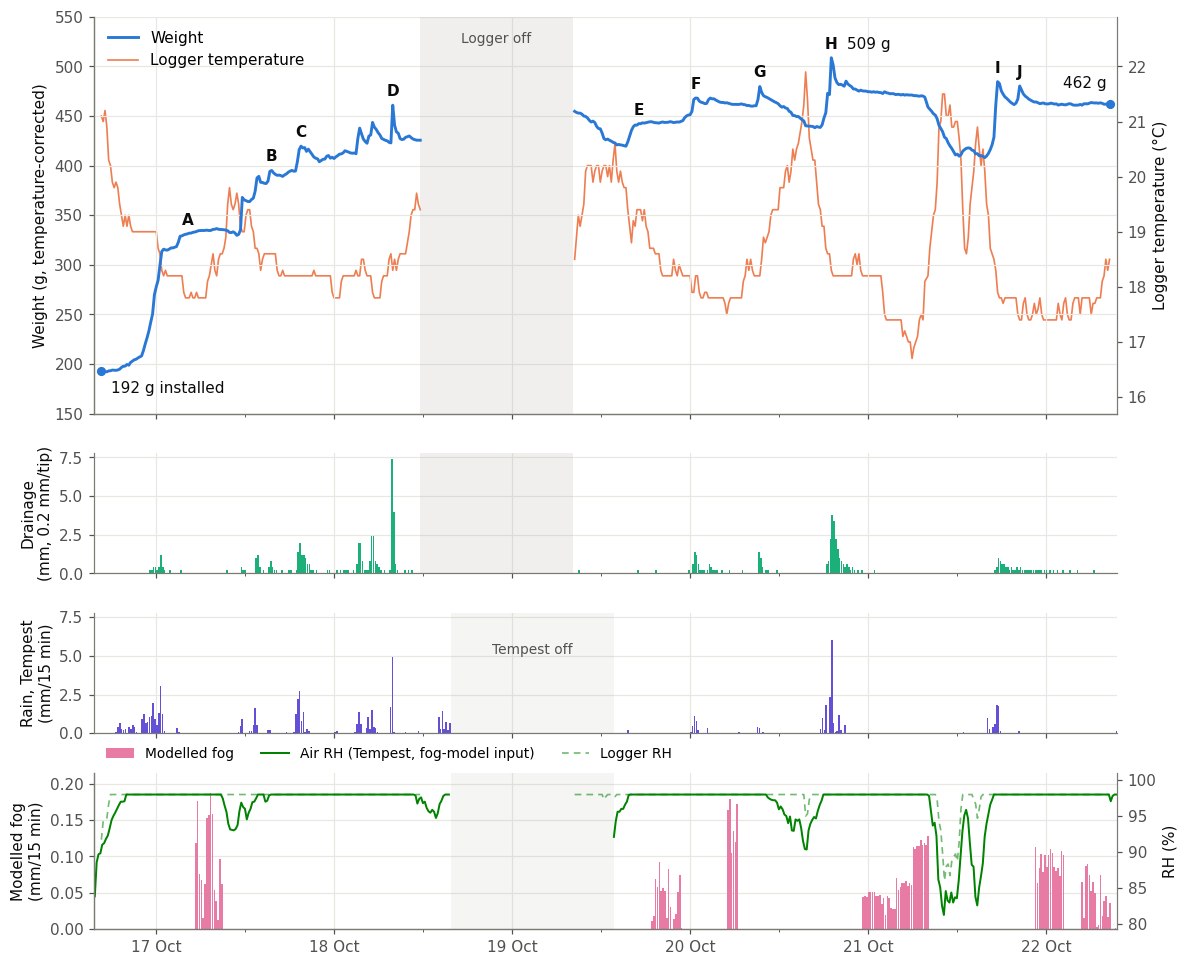

In [22]:
import matplotlib.ticker as mticker
x0, x1 = v.timestamp.min() - pd.Timedelta("1h"), v.timestamp.max() + pd.Timedelta("1h")
fz, tz = fog.loc[x0:x1], tem.loc[x0:x1]
bin_mid = pd.Timedelta("7.5min")
bar_w = 13 / 1440   # 13 min, in days

def shade_gaps(ax, label=False, y=None):
    for a, b in logger_gaps:
        ax.axvspan(a, b, color=MUTED, alpha=0.16, lw=0)
        if label:
            ax.text(a + (b - a) / 2, y, "Logger off", ha="center", va="top", color=TEXT2, fontsize=9)

def shade_tempest(ax, label=False):
    for a, b in tempest_gaps:
        ax.axvspan(a, b, color=MUTED, alpha=0.10, lw=0)
        if label:
            ax.text(a + (b - a) / 2, ax.get_ylim()[1] * 0.92, "Tempest off", ha="center", va="top", color=TEXT2, fontsize=9)

fig, (ax_w, ax_t, ax_r, ax_f) = plt.subplots(
    4, 1, figsize=(12, 10.5), sharex=True, gridspec_kw={"height_ratios": [3.3, 1, 1, 1.3], "hspace": 0.2})

# Absolute uncertainty of the weight (1 standard uncertainty): noise, temperature correction (residual, ALPHA
# uncertainty, extrapolation beyond the zero-test and calibration-session ranges), hysteresis, calibration error
# at field loads and tare
def weight_split(adc, t_zero, t_span):
    return (adc - ADC0 - ALPHA * (t_zero - T_REF)) * SLOPE / (1 + BETA * (t_span - T_REF))
t = v.avg_temperature_C
u_ext = (weight_split(v.avg_raw_adc, t, t)
         - weight_split(v.avg_raw_adc, t.clip(*ZERO_T_RANGE), t.clip(*CAL_T_RANGE))).abs()
u_alpha = U_ALPHA_FRAC * (ALPHA * SLOPE * (t - T_REF)).abs()
v["w_unc_g"] = np.sqrt(U_NOISE_G**2 + U_TEMP_G**2 + u_alpha**2 + u_ext**2 + U_HYST_G**2 + U_LIN_G**2 + U_TARE_G**2)
print(f"Absolute uncertainty of the weight: ±{v.w_unc_g.min():.1f} to ±{v.w_unc_g.max():.1f} g (1 standard uncertainty)")

# Weight (main) with logger temperature on the right axis
seg0 = v.segment.min()
for s, g in v.groupby("segment"):
    ax_w.plot(g.timestamp, g.weight_g, color=ACCENT, lw=1.9, zorder=3, label="Weight" if s == seg0 else None)
ax_w.set_ylabel("Weight (g, temperature-corrected)", color=TEXT)
ax_w.set_ylim(150, max(550, v.weight_g.max() + 40))
ax_T = ax_w.twinx()
for s, g in v.groupby("segment"):
    ax_T.plot(g.timestamp, g.avg_temperature_C, color=WARM, lw=1.1, alpha=0.85, label="Logger temperature" if s == seg0 else None)
ax_T.set_ylabel("Logger temperature (°C)", color=TEXT)
ax_T.spines["right"].set_visible(True)
ax_T.grid(False)
ax_T.set_ylim(v.avg_temperature_C.min() - 1, v.avg_temperature_C.max() + 1)
ax_w.set_zorder(ax_T.get_zorder() + 1); ax_w.patch.set_visible(False)   # weight drawn over temperature

for k, r in events.iterrows():
    ax_w.annotate(k, (r.t_peak, r.w_peak_g), xytext=(0, 6), textcoords="offset points", ha="center",
                  fontweight="bold", color=TEXT, zorder=5)
first, last = v.iloc[0], v.iloc[-1]
pk = v.loc[v.weight_g.idxmax()]
ax_w.annotate(f"{pk.weight_g:.0f} g", (pk.timestamp, pk.weight_g), xytext=(10, 6), textcoords="offset points", color=TEXT)
ax_w.plot([first.timestamp, last.timestamp], [first.weight_g, last.weight_g], "o", color=ACCENT, ms=5, zorder=4)
ax_w.annotate(f"{first.weight_g:.0f} g installed", (first.timestamp, first.weight_g), xytext=(6, -14),
              textcoords="offset points", color=TEXT)
ax_w.annotate(f"{last.weight_g:.0f} g", (last.timestamp, last.weight_g), xytext=(-2, 9),
              textcoords="offset points", ha="right", va="bottom", color=TEXT)
shade_gaps(ax_w, label=True, y=ax_w.get_ylim()[1] - 15)
h1, l1 = ax_w.get_legend_handles_labels(); h2, l2 = ax_T.get_legend_handles_labels()
ax_w.legend(h1 + h2, l1 + l2, loc="upper left")

# Drainage
ax_t.bar(v.timestamp - pd.Timedelta("7min"), v.drain_mm, width=bar_w, color=DRAIN)   # epiphyte share of each tip
ax_t.set_ylabel(f"Drainage\n(mm, {TIP_MM:.1f} mm/tip)", color=TEXT)
shade_gaps(ax_t)

# Rain (Tempest)
ax_r.bar(tz.index + bin_mid, tz.rain_mm, width=bar_w, color=RAIN)
ax_r.set_ylabel("Rain, Tempest\n(mm/15 min)", color=TEXT)
shade_tempest(ax_r, label=True)
ymax = max(v.drain_mm.max(), tz.rain_mm.max()) * 1.05
for ax in (ax_t, ax_r):   # same range, ticks and format on drainage and rain (both mm per ~15 min)
    ax.set_ylim(0, ymax)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(2.5))
    ax.yaxis.set_major_formatter(mticker.FormatStrFormatter("%.1f"))

# Modelled fog (FIESTA) with the fog flag shaded, and relative humidity on the right axis

ax_f.bar(fz.index + bin_mid, fz.fiesta_fog_mm, width=bar_w, color=FOG, label="Modelled fog")
ax_f.set_ylabel("Modelled fog\n(mm/15 min)", color=TEXT)
ax_f.set_ylim(0, max(fz.fiesta_fog_mm.max(), 0.01) * 1.15)
ax_RH = ax_f.twinx()
ax_RH.plot(fz.index, fz.RH_pct, color=HUMID, lw=1.3, label="Air RH (Tempest, fog-model input)")
for s, g in v.groupby("segment"):
    ax_RH.plot(g.timestamp, g.avg_humidity_pct, color=HUMID, lw=1.1, ls=(0, (4, 3)), alpha=0.55,
               label="Logger RH" if s == seg0 else None)
ax_RH.set_ylabel("RH (%)", color=TEXT)
ax_RH.set_ylim(min(fz.RH_pct.min(), v.avg_humidity_pct.min()) - 2, 101)
ax_RH.spines["right"].set_visible(True)
ax_RH.grid(False)
shade_tempest(ax_f)
h1, l1 = ax_f.get_legend_handles_labels(); h2, l2 = ax_RH.get_legend_handles_labels()
ax_f.legend(h1 + h2, l1 + l2, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=9)

ax_f.xaxis.set_major_locator(mdates.DayLocator())
ax_f.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax_f.xaxis.set_minor_locator(mdates.HourLocator(byhour=[12]))
ax_f.set_xlim(x0, x1)

days = round((last.timestamp - first.timestamp).total_seconds() / 86400)
fig.subplots_adjust(top=0.90)

fig.savefig(OUT_DIR / "lysimeter_field_weight.png")
plt.show()

## 6. Event analysis

Per event: input to the epiphyte (throughfall + fog), drainage, change in storage, and the **closure ratio** (D + ΔS) / P. If inputs and outputs were all measured well, the ratio would sit just below 1 (the rest being evaporation).

**Interpretation (16–22 Oct, 10 events, drainage at 0.2 mm per tip):** the first storm (A) filled the dry mat with 5.1 mm, while 4.0 mm drained, less than its input (ratio 0.67). Every later event drained more than the gauge says reached the epiphyte (ratios 1.3–2.7, ignoring the small events E, G and J). Storage after each storm climbed to about 10 mm by 20 Oct and returned there after storms I and J on 21 Oct, which refilled what the sunny morning had dried out. That points to a holding capacity of roughly 10 mm (about 280 g). Intense storms held a further 0.4–1.2 mm briefly, which drained within about an hour. The ratio swings too much between events to come from a fixed bucket error. A mismatch between the gauge and the epiphyte's real input is the likelier main cause.

,start,end,rain_tempest_mm,P_epi_mm,tips,drain_mm,peak_gain_mm,net_gain_mm,transient_mm,storage_after_mm,ET_residual_mm,closure_ratio
event,,,,,,,,,,,,
A,2026-10-16 18:51:13,2026-10-17 03:15:03,18.99,13.48,20,4.0,5.06,5.06,0.00,5.11,4.42,0.67
B,2026-10-17 11:08:57,2026-10-17 15:36:03,4.85,5.90,28,5.6,2.38,2.20,0.17,7.30,-1.91,1.32
C,2026-10-17 18:33:57,2026-10-17 20:47:48,8.94,3.47,44,8.8,0.93,0.46,0.47,7.90,-5.79,2.67
D,2026-10-18 02:58:29,2026-10-18 07:55:40,13.23,9.92,131,26.2,1.80,0.56,1.24,8.65,-16.84,2.70
E,2026-10-19 15:22:33,2026-10-19 16:21:51,0.27,0.27,1,0.2,0.84,0.84,0.00,9.20,-0.76,3.82
F,2026-10-20 00:01:32,2026-10-20 02:30:09,3.06,4.53,30,6.0,0.62,0.55,0.08,10.08,-2.02,1.45
G,2026-10-20 08:55:52,2026-10-20 09:55:21,0.85,1.58,16,3.2,0.71,0.23,0.48,10.10,-1.85,2.17
H,2026-10-20 17:35:02,2026-10-20 21:03:17,14.61,12.44,95,19.0,2.59,1.43,1.16,10.50,-7.98,1.64
I,2026-10-21 16:00:36,2026-10-21 17:59:22,6.00,3.97,22,4.4,2.76,2.07,0.70,10.07,-2.49,1.63


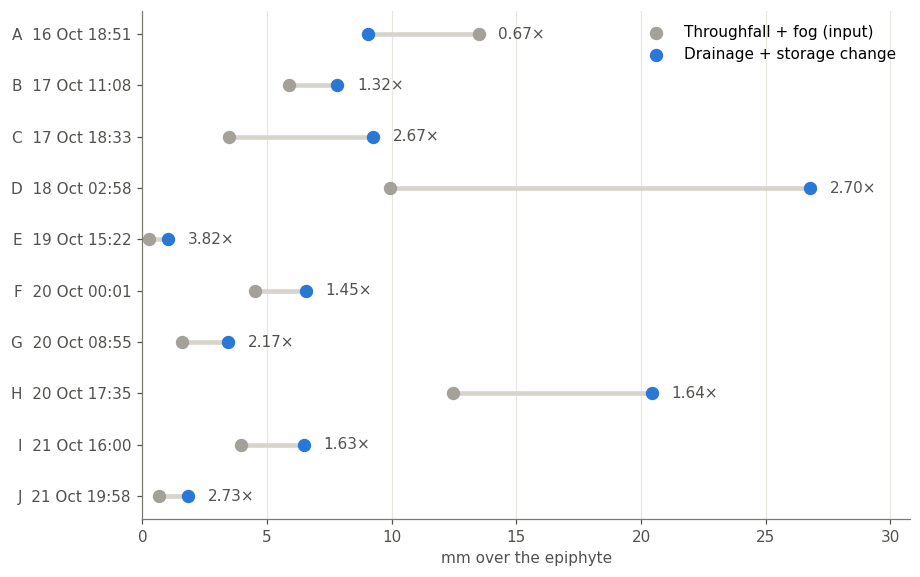

In [23]:
cols = ["start", "end", "rain_tempest_mm", "P_epi_mm", "tips", "drain_mm", "peak_gain_mm", "net_gain_mm",
        "transient_mm", "storage_after_mm", "ET_residual_mm", "closure_ratio"]
display(rnd(events[cols]))

# Dumbbell: measured input vs drainage + storage, per event
ev = events.iloc[::-1]
out_mm = ev.drain_mm + ev.net_gain_mm
fig, ax = plt.subplots(figsize=(9, 1.2 + 0.48 * len(ev)))
y = np.arange(len(ev))
ax.hlines(y, ev.P_epi_mm, out_mm, color=MUTED_LIGHT, lw=3, zorder=1)
ax.scatter(ev.P_epi_mm, y, s=60, color=MUTED, zorder=2, label="Throughfall + fog (input)")
ax.scatter(out_mm, y, s=60, color=ACCENT, zorder=3, label="Drainage + storage change")
for yi, (k, r) in zip(y, ev.iterrows()):
    if np.isfinite(r.closure_ratio):
        ax.text(max(r.P_epi_mm, r.drain_mm + r.net_gain_mm) + 0.8, yi, f"{r.closure_ratio:.2f}×", va="center", color=TEXT2)
ax.set_yticks(y, [f"{k}  {r.start:%d %b %H:%M}" for k, r in ev.iterrows()])
ax.set_xlabel("mm over the epiphyte")
ax.set_xlim(min(0, out_mm.min() - 1), max(out_mm.max(), ev.P_epi_mm.max()) * 1.15)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper right")
n_over = int((events.closure_ratio > 1).sum())
fig.savefig(OUT_DIR / "lysimeter_event_closure.png")
plt.show()

## 7. Water balance

Cumulative input (throughfall + fog on the epiphyte) against drainage plus storage, restarting after each logger outage because drainage during an outage was not recorded. The gap between the two lines at the end of a segment is the residual ET.

**Interpretation (16–22 Oct, drainage at 0.2 mm per tip):** the balance still does not close. Attributing each tip to the epiphyte in proportion to its area already removes the share of bucket water that fell straight into the funnel. Even so, drainage plus storage exceeded the measured input by 17.5 mm (16–18 Oct, ratio 1.45) and 7.5 mm (19–22 Oct, ratio 1.22). Over the whole record, 88.8 mm drained against 72.7 mm of throughfall and fog. In rain-free windows the balance and the weight loss agree, so the method works. The remaining gap points to the epiphyte receiving more water than the throughfall gauge records (canopy drip, wind-driven rain), or to the bucket over-counting.

,start,end,rain_tempest_mm,tf_mm,fog_model_mm,fog_epi_mm,P_epi_mm,tips,drain_mm,dS_mm,ET_residual_mm,closure_ratio
segment,,,,,,,,,,,,
1,2026-10-16 16:38:09,2026-10-18 11:38:13,46.97,37.95,1.44,0.54,38.49,238,47.6,8.59,-17.70,1.46
2,2026-10-19 08:27:25,2026-10-22 08:35:15,25.48,32.28,6.12,2.31,34.59,206,41.2,0.26,-6.87,1.20


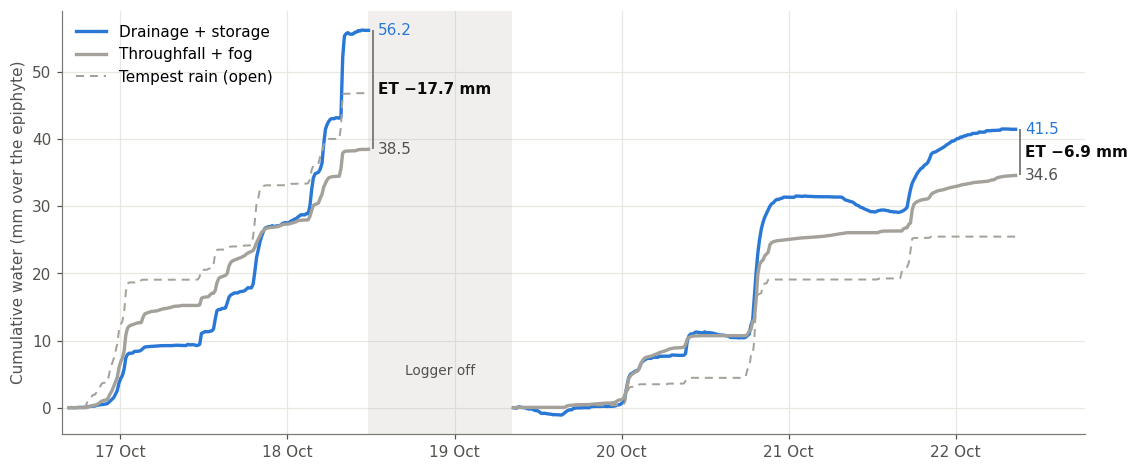

In [24]:
segments, cum = [], []
for s, a in v.groupby("segment"):
    b = a.iloc[1:]   # increments after the segment's first record
    dS = (a.weight_g.iloc[-1] - a.weight_g.iloc[0]) * G_TO_MM
    row = dict(segment=s, start=a.timestamp.iloc[0], end=a.timestamp.iloc[-1],
               rain_tempest_mm=b.rain_mm.sum(), tf_mm=b.tf_mm.sum(), fog_model_mm=b.fog_model_mm.sum(),
               fog_epi_mm=b.fog_epi_mm.sum(), P_epi_mm=b.P_epi_mm.sum(), tips=int(b.tips.sum()),
               drain_mm=b.drain_mm.sum(), dS_mm=dS)
    row["ET_residual_mm"] = row["P_epi_mm"] - row["drain_mm"] - dS
    row["closure_ratio"] = (row["drain_mm"] + dS) / row["P_epi_mm"]
    segments.append(row)
    c = a[["timestamp", "segment"]].copy()
    c["cum_rain_mm"] = np.r_[0, b.rain_mm.cumsum()]
    c["cum_P_mm"] = np.r_[0, b.P_epi_mm.cumsum()]
    c["cum_D_mm"] = np.r_[0, b.drain_mm.cumsum()]
    c["dS_mm"] = (a.weight_g - a.weight_g.iloc[0]).values * G_TO_MM
    c["cum_out_mm"] = c.cum_D_mm + c.dS_mm
    c["residual_ET_mm"] = c.cum_P_mm - c.cum_out_mm
    cum.append(c)
segments = pd.DataFrame(segments).set_index("segment")
cum = pd.concat(cum)
display(rnd(segments))

fig, ax = plt.subplots(figsize=(12, 5))
for s, c in cum.groupby("segment"):
    ax.plot(c.timestamp, c.cum_out_mm, color=ACCENT, lw=2.2, label="Drainage + storage" if s == seg0 else None)
    ax.plot(c.timestamp, c.cum_P_mm, color=MUTED, lw=2.2, label="Throughfall + fog" if s == seg0 else None)
    ax.plot(c.timestamp, c.cum_rain_mm, color=MUTED, lw=1.3, ls=(0, (4, 3)), label="Tempest rain (open)" if s == seg0 else None)
    e = c.iloc[-1]
    ax.vlines(e.timestamp + pd.Timedelta("40min"), e.cum_P_mm, e.cum_out_mm, color=REF, lw=1.2)
    ax.text(e.timestamp + pd.Timedelta("80min"), (e.cum_P_mm + e.cum_out_mm) / 2,
            f"ET {e.residual_ET_mm:+.1f} mm".replace("-", "−"), va="center", fontweight="bold", color=TEXT)
    ax.text(e.timestamp + pd.Timedelta("80min"), e.cum_out_mm, f"{e.cum_out_mm:.1f}", va="center", color=ACCENT)
    ax.text(e.timestamp + pd.Timedelta("80min"), e.cum_P_mm, f"{e.cum_P_mm:.1f}", va="center", color=TEXT2)
shade_gaps(ax, label=True, y=ax.get_ylim()[1] * 0.06 + 3)
ax.set_ylabel("Cumulative water (mm over the epiphyte)")
ax.xaxis.set_major_locator(mdates.DayLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_xlim(v.timestamp.min() - pd.Timedelta("1h"), v.timestamp.max() + pd.Timedelta("10h"))
ax.legend(loc="upper left")
neg = (segments.ET_residual_mm < 0).all()
fig.savefig(OUT_DIR / "lysimeter_water_balance.png")
plt.show()

## 8. Fog

Weight change during fog windows, compared with the modelled fog over the epiphyte's fog-facing area (102.6 cm²). A clean fog check needs a window with no drainage, while the mat is below capacity.

**Interpretation (16–22 Oct):** the one clean window (17 Oct, before sunrise, no drainage) gained 0.62 mm over the fog-facing area, 91% of the modelled 0.68 mm. The 19 Oct evening window gained 62% of the modelled fog with one tip of drainage, so that is a lower bound. On the other fog nights the mat was still draining after a storm. Modelled fog adds about 3% of the epiphyte's input (2.4 mm over 42 h of fog).

In [25]:
def window_rows(t0, t1):
    a = v[(v.timestamp >= pd.Timestamp(t0)) & (v.timestamp <= pd.Timestamp(t1))]
    return a, a.iloc[1:]

fog_rows = []
for t0, t1, note in fog_list:
    a, b = window_rows(t0, t1)
    dWf = a.weight_g.iloc[-1] - a.weight_g.iloc[0]
    over_fog_area = dWf * 10 / FOG_AREA_CM2
    fm = b.fog_model_mm.sum()
    fog_rows.append(dict(start=a.timestamp.iloc[0], end=a.timestamp.iloc[-1],
                         hours=(a.timestamp.iloc[-1] - a.timestamp.iloc[0]).total_seconds() / 3600,
                         fog_model_mm=fm, weight_change_g=dWf, weight_change_unc_g=u_change_g(a),
                         over_fog_area_mm=over_fog_area,
                         measured_over_modelled=over_fog_area / fm if (dWf > 0 and fm > 0) else np.nan,
                         tips=int(b.tips.sum()), drain_mm=b.drain_mm.sum(), tf_mm=b.tf_mm.sum(), note=note))
fog_windows = pd.DataFrame(fog_rows)
display(rnd(fog_windows))
print(f"Fog flagged for {v.fog.sum() * 0.25:.1f} h; modelled fog {v.fog_model_mm.sum():.1f} mm "
      f"= {v.fog_epi_mm.sum():.1f} mm on the epiphyte "
      f"({v.fog_epi_mm.sum() / v.P_epi_mm.sum():.0%} of throughfall + fog on the epiphyte)")

,start,end,hours,fog_model_mm,weight_change_g,weight_change_unc_g,over_fog_area_mm,measured_over_modelled,tips,drain_mm,tf_mm,note
0,2026-10-17 05:13:33,2026-10-17 08:11:12,2.96,1.26,3.48,1.96,0.34,0.27,0,0.0,0.24,no drainage
1,2026-10-19 18:50:09,2026-10-19 23:02:13,4.20,0.70,1.10,1.96,0.11,0.15,1,0.2,0.06,draining (1 tips)
2,2026-10-20 23:17:01,2026-10-21 07:26:11,8.15,2.00,-5.19,1.97,-0.51,NaN,1,0.2,0.18,draining (1 tips)
3,2026-10-21 22:27:01,2026-10-22 02:24:29,3.96,1.48,-2.62,1.96,-0.25,NaN,10,2.0,0.39,draining (10 tips)
4,2026-10-22 05:22:26,2026-10-22 07:35:55,2.22,0.50,0.42,1.96,0.04,0.08,1,0.2,0.41,draining (1 tips)


Fog flagged for 26.2 h; modelled fog 7.6 mm = 2.9 mm on the epiphyte (4% of throughfall + fog on the epiphyte)


## 9. Evapotranspiration from mass loss

In rain-free daytime windows nothing enters the epiphyte, so its mass loss is its evapotranspiration (ET ≈ −ΔS, plus any drainage). The lysimeter weighs the whole plant with its water, so the loss includes evaporation of water held on and in the epiphyte *and* any transpiration; a weighing lysimeter cannot separate the two. Mass changes from photosynthesis and respiration are negligible against water over a few hours. Balance ET also subtracts any tips that fell. When the two differ, those slow drips are either real drainage (mass loss slightly overstates ET) or false counts.

**Interpretation (16–22 Oct):** drying rates follow the sky and the air. The clear 21 Oct morning (mean radiation 371 W/m², RH 87%) dried the mat at 0.40 mm/h, losing 1.7 mm in about 4 h. Cloudier windows on 19 and 20 Oct ran at 0.16–0.22 mm/h, with RH at 92–94%. The temperature correction shifts each window by 0.1–0.2 mm, so changes under ~0.15 mm over a few hours are within calibration uncertainty.

In [26]:
dry_rows = []
for t0, t1 in dry_list:
    a, b = window_rows(t0, t1)
    h = (a.timestamp.iloc[-1] - a.timestamp.iloc[0]).total_seconds() / 3600
    dS = (a.weight_g.iloc[-1] - a.weight_g.iloc[0]) * G_TO_MM
    dS_uncorr = (a.weight_uncorr_g.iloc[-1] - a.weight_uncorr_g.iloc[0]) * G_TO_MM
    u = u_change_g(a)
    dry_rows.append(dict(start=a.timestamp.iloc[0], end=a.timestamp.iloc[-1], hours=h,
                         mass_loss_g=-dS / G_TO_MM, mass_loss_unc_g=u, rate_g_h=-dS / G_TO_MM / h,
                         ET_mass_loss_mm=-dS, ET_unc_mm=u * G_TO_MM, rate_mm_h=-dS / h, ET_mass_loss_uncorrected_mm=-dS_uncorr,
                         tips=int(b.tips.sum()), ET_balance_mm=b.P_epi_mm.sum() - b.drain_mm.sum() - dS,
                         rad_wm2=b.rad_wm2.mean(), rh_air=b.rh_air.mean(), logger_T_max=a.avg_temperature_C.max()))
dry = pd.DataFrame(dry_rows)
display(rnd(dry, 3))

,start,end,hours,mass_loss_g,mass_loss_unc_g,rate_g_h,ET_mass_loss_mm,ET_unc_mm,rate_mm_h,ET_mass_loss_uncorrected_mm,tips,ET_balance_mm,rad_wm2,rh_air,logger_T_max
0,2026-10-19 08:27:25,2026-10-19 13:53:36,5.436,31.885,2.234,5.865,1.175,0.082,0.216,0.957,1,1.020,161.182,92.091,20.6
1,2026-10-20 11:54:05,2026-10-20 17:20:13,5.436,23.622,2.079,4.346,0.871,0.077,0.160,0.859,0,0.871,124.534,93.962,21.9
2,2026-10-21 08:21:02,2026-10-21 12:33:06,4.201,45.904,2.422,10.927,1.692,0.089,0.403,1.525,0,1.692,370.937,87.027,21.5
3,2026-10-21 13:17:33,2026-10-21 15:45:47,2.471,9.477,2.008,3.836,0.349,0.074,0.141,0.195,0,0.409,315.247,88.420,20.9


### Figure 5: fog gain and drying in detail

Two parts of the record at higher resolution, picked automatically: (a) the cleanest fog window (no drainage, largest measured/modelled ratio) and (b) the day with the fastest drying window. Each column shows the epiphyte's mass, modelled fog with air humidity, and solar radiation. Shading marks the fog window in (a) and the drying windows in (b). The dashed line in (a) is the radiation threshold where the fog window stops, because evaporation starts to mask fog gains after sunrise.

Band in Figure 5: ±1.4 g per reading


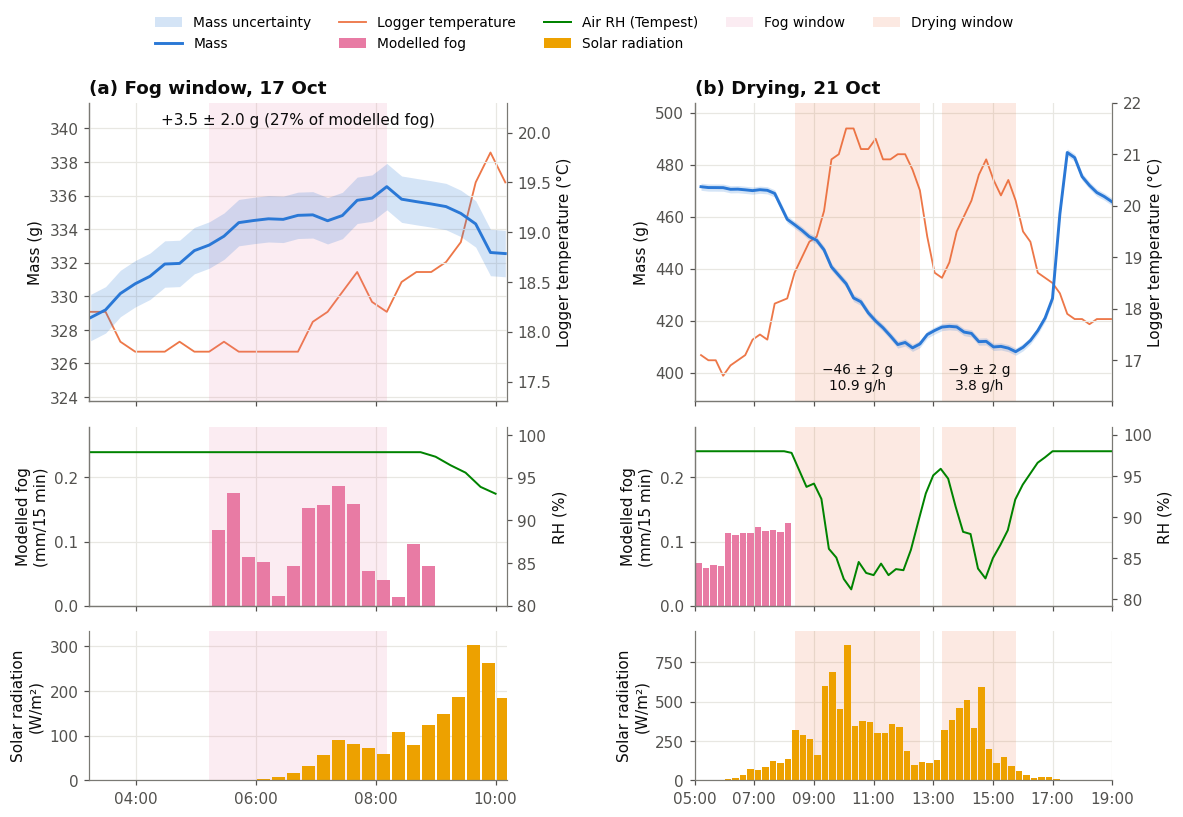

In [27]:
SUN = "#eda100"   # solar radiation
# Uncertainty of a single reading for comparisons within a few hours: noise and temperature-correction residual.
# Two readings combined give the uncertainty of a window's mass change (about ±2 g, Section 9).
U_READING_G = np.sqrt(U_NOISE_G**2 / 2 + U_TEMP_G**2)
print(f"Band in Figure 5: ±{U_READING_G:.1f} g per reading")

# (a) cleanest fog window: no drainage, largest measured/modelled ratio
clean = fog_windows[(fog_windows.tips == 0) & fog_windows.measured_over_modelled.notna()]
fw = (clean if len(clean) else fog_windows).sort_values("measured_over_modelled", ascending=False).iloc[0]
a0, a1 = fw.start - pd.Timedelta("2h"), fw.end + pd.Timedelta("2h")
# (b) the day of the fastest drying window
fastest = dry.loc[dry.rate_mm_h.idxmax()]
day = fastest.start.normalize()
b0, b1 = day + pd.Timedelta("5h"), day + pd.Timedelta("19h")
day_windows = dry[(dry.start >= day) & (dry.start < day + pd.Timedelta("1D"))]

fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex="col",
                         gridspec_kw={"height_ratios": [2, 1.2, 1], "hspace": 0.12, "wspace": 0.45})

def zoom_column(axcol, t0, t1, shade, shade_color):
    ax_m, ax_f, ax_s = axcol
    vv = v[(v.timestamp >= t0) & (v.timestamp <= t1)]
    ff, tt = fog.loc[t0:t1], tem.loc[t0:t1]
    for ax in (ax_m, ax_f, ax_s):
        for s0, s1 in shade:
            ax.axvspan(s0, s1, color=shade_color, alpha=0.14, lw=0)
    # mass, with logger temperature on the right axis
    for s, g in vv.groupby("segment"):
        ax_m.fill_between(g.timestamp, g.weight_g - U_READING_G, g.weight_g + U_READING_G, color=ACCENT, alpha=0.2,
                          lw=0, label="Mass uncertainty" if s == vv.segment.min() else None)
        ax_m.plot(g.timestamp, g.weight_g, color=ACCENT, lw=1.9, label="Mass" if s == vv.segment.min() else None)
    ax_m.set_ylabel("Mass (g)", color=TEXT)
    pad = max(5, (vv.weight_g.max() - vv.weight_g.min()) * 0.25)
    ax_m.set_ylim(vv.weight_g.min() - pad, vv.weight_g.max() + pad)
    ax_T = ax_m.twinx()
    for s, g in vv.groupby("segment"):
        ax_T.plot(g.timestamp, g.avg_temperature_C, color=WARM, lw=1.2, alpha=0.9,
                  label="Logger temperature" if s == vv.segment.min() else None)
    ax_T.set_ylabel("Logger temperature (°C)", color=TEXT)
    ax_T.set_ylim(vv.avg_temperature_C.min() - 0.5, vv.avg_temperature_C.max() + 0.5)
    ax_T.spines["right"].set_visible(True); ax_T.grid(False)
    ax_m.set_zorder(ax_T.get_zorder() + 1); ax_m.patch.set_visible(False)   # mass drawn over temperature
    # modelled fog bars with RH on the right axis
    ax_f.bar(ff.index + bin_mid, ff.fiesta_fog_mm, width=bar_w, color=FOG, label="Modelled fog")
    ax_f.set_ylabel("Modelled fog\n(mm/15 min)", color=TEXT)
    ax_f.set_ylim(0, max(fog.fiesta_fog_mm.max(), 0.01) * 1.15)
    ax_h = ax_f.twinx()
    ax_h.plot(ff.index, ff.RH_pct, color=HUMID, lw=1.3, label="Air RH (Tempest)")
    ax_h.set_ylabel("RH (%)", color=TEXT)
    ax_h.set_ylim(min(80, ff.RH_pct.min() - 2), 101)
    ax_h.spines["right"].set_visible(True); ax_h.grid(False)
    # solar radiation
    ax_s.bar(tt.index + bin_mid, tt.solar_radiation, width=bar_w, color=SUN, label="Solar radiation")   # bars, like modelled fog
    ax_s.set_ylabel("Solar radiation\n(W/m²)", color=TEXT)
    ax_s.set_ylim(0, max(50, tt.solar_radiation.max() * 1.1))
    ax_s.xaxis.set_major_locator(mdates.HourLocator(interval=2))
    ax_s.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_s.set_xlim(t0, t1)
    return ax_m, ax_T, ax_f, ax_h, ax_s

# (a) fog
ax_m, ax_T, ax_f, ax_h, ax_s = zoom_column(axes[:, 0], a0, a1, [(fw.start, fw.end)], FOG)
ax_m.set_title(f"(a) Fog window, {fw.start:%d %b}", loc="left")
ax_m.annotate(f"{fw.weight_change_g:+.1f} ± {fw.weight_change_unc_g:.1f} g ({fw.measured_over_modelled:.0%} of modelled fog)",
              (fw.start + (fw.end - fw.start) / 2, ax_m.get_ylim()[1]), xytext=(0, -6), textcoords="offset points",
              ha="center", va="top", color=TEXT)
legend_axes = (ax_m, ax_T, ax_f, ax_h, ax_s)   # column (a) has every series

# (b) drying
ax_m, ax_T, ax_f, ax_h, ax_s = zoom_column(axes[:, 1], b0, b1, list(zip(day_windows.start, day_windows.end)), WARM)
ax_m.set_title(f"(b) Drying, {day:%d %b}", loc="left")
for r in day_windows.itertuples():
    ax_m.annotate(f"−{r.mass_loss_g:.0f} ± {r.mass_loss_unc_g:.0f} g\n{r.rate_g_h:.1f} g/h",
                  (r.start + (r.end - r.start) / 2, ax_m.get_ylim()[0]), xytext=(0, 6), textcoords="offset points",
                  ha="center", va="bottom", color=TEXT, fontsize=9)

# One legend at the top for all panels
from matplotlib.patches import Patch
handles, labels = [], []
for ax in legend_axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        if l not in labels:
            handles.append(h); labels.append(l)
handles += [Patch(facecolor=FOG, alpha=0.14), Patch(facecolor=WARM, alpha=0.14)]
labels += ["Fog window", "Drying window"]
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.925), ncol=5, fontsize=9)

fig.savefig(OUT_DIR / "lysimeter_fog_drying_zoom.png")
plt.show()

## 10. Data-quality checks

Each check is computed from the files, so it reruns on new data. A fourth figure shows the logger temperature against the calibration range and how large the temperature correction is.

,check,finding,consequence
0,Readings outside the zero-test range,0.4% outside 16.9–21.7 °C; field 16.7–21.9 °C,zero correction (ALPHA) applies to almost all ...
1,Readings outside the calibration-session range,"58% below 18.6 °C, 1% above 21.4 °C",span correction (BETA) extrapolated; with the ...
2,Mass uncertainty,noise 0.66 g per 15-min change; absolute ±7 g ...,changes over a window: see the uncertainty col...
3,Tare temperature,"tare row logged at 21.0 °C, T_REF = 21 °C",possible constant offset of +0.0 g
4,Temperature correction size,-2.5 to 12.2 g,added to the uncorrected weight
5,Logger RH saturated,94% of records at 98%,no fog signal from the logger
6,Sampling interval,median 890 s; elapsed_sec steps 900 s,elapsed_sec drifts 1.1% against the clock
7,Boot counter,boot_session values: [1]; boots found: 2,counter does not increment
8,Tip-counter resets,"19 Oct 08:12 (BOOT_POWERON, counter was 238, w...","tips taken as the count since the reset, never..."
9,First record after a reboot,2026-10-19 08:12:34: 304 g,"partial average, dropped"


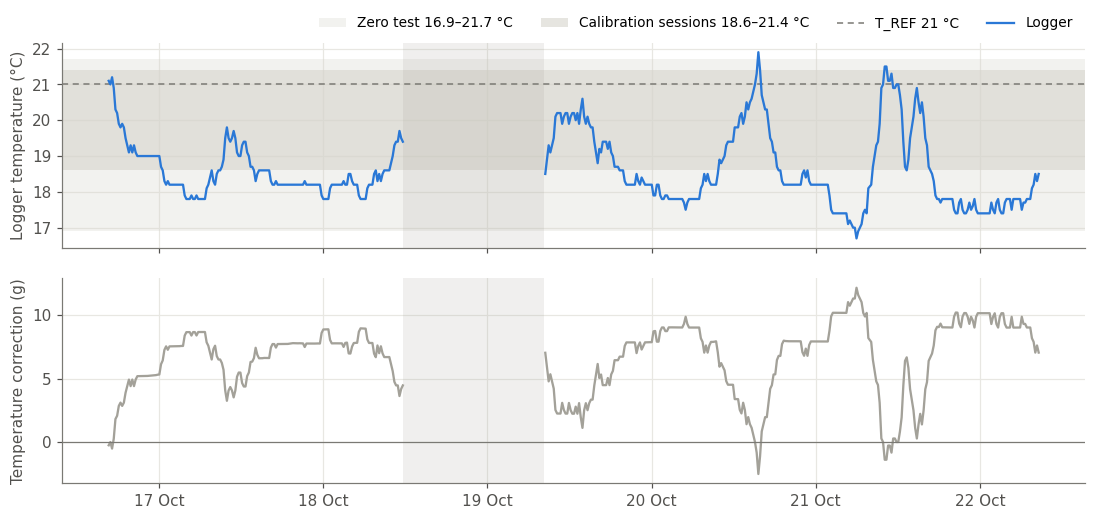

In [28]:
lo, hi = CAL_T_RANGE
tz = v.avg_temperature_C
interval_s = lys_raw.timestamp.diff().dt.total_seconds()
elapsed_step = lys_raw.elapsed_sec.diff()
first_after_boot = lys[lys.is_boot & (lys.index > 0)][["timestamp", "avg_raw_adc", "weight_g"]]
fog_ratio = (tem["precip"] * TEMPEST_PRECIP_TO_MM).sum() / fog["rain_mm"].sum()
corr = v.weight_g - v.weight_uncorr_g

checks = pd.DataFrame([
    ("Readings outside the zero-test range", f"{(~tz.between(*ZERO_T_RANGE)).mean():.1%} outside "
     f"{ZERO_T_RANGE[0]}–{ZERO_T_RANGE[1]} °C; field {tz.min():.1f}–{tz.max():.1f} °C",
     "zero correction (ALPHA) applies to almost all readings"),
    ("Readings outside the calibration-session range", f"{(tz < lo).mean():.0%} below {lo} °C, {(tz > hi).mean():.0%} above {hi} °C",
     f"span correction (BETA) extrapolated; with the zero part, changes the weight by at most {u_ext.max():.1f} g"),
    ("Mass uncertainty", f"noise {U_NOISE_G:.2f} g per 15-min change; absolute ±{v.w_unc_g.max():.0f} g (1 SD)",
     "changes over a window: see the uncertainty columns of the drying and fog tables"),
    ("Tare temperature", f"tare row logged at {lys_raw.avg_temperature_C.iloc[0]} °C, T_REF = {T_REF} °C",
     f"possible constant offset of {lys.weight_g.iloc[0]:+.1f} g"),
    ("Temperature correction size", f"{corr.min():.1f} to {corr.max():.1f} g", "added to the uncorrected weight"),
    ("Logger RH saturated", f"{(v.avg_humidity_pct >= 98).mean():.0%} of records at 98%", "no fog signal from the logger"),
    ("Sampling interval", f"median {interval_s.median():.0f} s; elapsed_sec steps {elapsed_step.mode().iloc[0]:.0f} s",
     f"elapsed_sec drifts {(elapsed_step.mode().iloc[0] / interval_s.median() - 1):.1%} against the clock"),
    ("Boot counter", f"boot_session values: {sorted(int(x) for x in lys_raw.boot_session.unique())}; boots found: {int(lys.is_boot.sum())}",
     "counter does not increment" if lys_raw.boot_session.nunique() < lys.is_boot.sum() else "ok"),
    ("Tip-counter resets", "; ".join(f"{r.timestamp:%d %b %H:%M} ({r.kind}, counter was {r.tips_before:.0f}, "
                                     f"weight {r.weight_after_g - r.weight_before_g:+.0f} g)"
                                     for r in resets.iloc[1:].itertuples()) or "none",
     "tips taken as the count since the reset, never negative; tips in the minutes before a silent reset are lost"),
    ("First record after a reboot", "; ".join(f"{r.timestamp}: {r.weight_g:.0f} g" for r in first_after_boot.itertuples()) or "none",
     "partial average, dropped"),
    ("Logger outages", "; ".join(f"{a} to {b}" for a, b in logger_gaps) or "none", "drainage not recorded; tip counter resets"),
    ("Tempest gaps", "; ".join(f"{a} to {b}" for a, b in tempest_gaps) or "none", "rain unknown in these spans"),
    ("Rain scaling in fog file", f"Tempest rain / fog-file rain_mm = {fog_ratio:.1f}", "use Tempest precip x 15"),
    ("Drainage vs input", f"{segments.drain_mm.sum():.1f} mm drained vs {segments.P_epi_mm.sum():.1f} mm throughfall + fog",
     "water balance does not close"),
], columns=["check", "finding", "consequence"])
display(checks)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 5.2), sharex=True, gridspec_kw={"hspace": 0.15})
a1.axhspan(*ZERO_T_RANGE, color=MUTED_LIGHT, alpha=0.3, lw=0, label=f"Zero test {ZERO_T_RANGE[0]}–{ZERO_T_RANGE[1]} °C")
a1.axhspan(lo, hi, color=MUTED_LIGHT, alpha=0.6, lw=0, label=f"Calibration sessions {lo}–{hi} °C")
a1.axhline(T_REF, color=REF, lw=1, ls=(0, (4, 3)), label=f"T_REF {T_REF} °C")
for s, g in v.groupby("segment"):
    a1.plot(g.timestamp, g.avg_temperature_C, color=ACCENT, lw=1.5, label="Logger" if s == v.segment.iloc[0] else None)
a1.set_ylabel("Logger temperature (°C)")
a1.legend(loc="lower right", bbox_to_anchor=(1, 1.0), ncol=4, fontsize=9)
for s, g in v.groupby("segment"):
    a2.plot(g.timestamp, (g.weight_g - g.weight_uncorr_g), color=MUTED, lw=1.5)
a2.set_ylabel("Temperature correction (g)")
for ax in (a1, a2):
    shade_gaps(ax)
a2.axhline(0, color=REF, lw=0.8)
a2.xaxis.set_major_locator(mdates.DayLocator()); a2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.savefig(OUT_DIR / "lysimeter_temperature_correction.png")
plt.show()

## 11. Summary

Computed headline numbers. Compare them with the report, or rerun after adding data.

In [29]:
s = segments
dry_main = dry[dry.hours >= 3]
clean_fog = fog_windows.dropna(subset=["measured_over_modelled"]).iloc[0] if fog_windows.measured_over_modelled.notna().any() else None
lines = [
    f"- **Storage:** {v.weight_g.iloc[0]:.0f} g at installation → {v.weight_g.iloc[-1]:.0f} g on {v.timestamp.iloc[-1]:%d %b %H:%M}: "
    f"{v.storage_mm.iloc[-1]:.1f} mm of water over {AREA_CM2:.0f} cm² (peak {v.storage_mm.max():.1f} mm).",
    f"- **Storm response:** transient storage of {events.transient_mm[events.transient_mm > 0.3].min():.1f}–{events.transient_mm.max():.1f} mm "
    "drained within about an hour of the intense storms.",
    f"- **Drainage vs input:** {int(v.tips.sum())} tips = {v.tips.sum() * TIP_ML / 1000:.2f} L in the bucket, of which "
    f"{v.tips.sum() * TIP_ML_EPI / 1000:.2f} L ({v.drain_mm.sum():.1f} mm) is attributed to the epiphyte, against "
    f"{s.tf_mm.sum():.1f} mm throughfall and {s.fog_epi_mm.sum():.1f} mm modelled fog on the epiphyte.",
    "- **Water balance:** residual ET " + ", ".join(f"{r.ET_residual_mm:+.1f} mm ({r.start:%d %b}–{r.end:%d %b}, ratio {r.closure_ratio:.2f})"
                                                     for r in s.itertuples()) + ".",
]
if len(dry_main):
    lines.append("- **ET from mass loss:** " + "; ".join(
        f"{r.start:%d %b} {r.start:%H:%M}–{r.end:%H:%M}: {r.ET_mass_loss_mm:.2f} mm ({r.rate_mm_h:.2f} mm/h)"
        for r in dry_main.itertuples()) + ".")
if clean_fog is not None:
    lines.append(f"- **Fog check:** {clean_fog.start:%d %b} window gained {clean_fog.over_fog_area_mm:.2f} mm over the fog-facing area, "
                 f"{clean_fog.measured_over_modelled:.0%} of the modelled {clean_fog.fog_model_mm:.2f} mm.")
lines.append(f"- **Temperature:** {(v.avg_temperature_C < CAL_T_RANGE[0]).mean():.0%} of readings below the calibration range.")
display(Markdown("\n".join(lines)))

- **Storage:** 192 g at installation → 462 g on 22 Oct 08:35: 9.9 mm of water over 271 cm² (peak 11.7 mm).
- **Storm response:** transient storage of 0.4–1.2 mm drained within about an hour of the intense storms.
- **Drainage vs input:** 444 tips = 2.79 L in the bucket, of which 2.41 L (88.8 mm) is attributed to the epiphyte, against 70.2 mm throughfall and 2.9 mm modelled fog on the epiphyte.
- **Water balance:** residual ET -17.7 mm (16 Oct–18 Oct, ratio 1.46), -6.9 mm (19 Oct–22 Oct, ratio 1.20).
- **ET from mass loss:** 19 Oct 08:27–13:53: 1.18 mm (0.22 mm/h); 20 Oct 11:54–17:20: 0.87 mm (0.16 mm/h); 21 Oct 08:21–12:33: 1.69 mm (0.40 mm/h).
- **Fog check:** 17 Oct window gained 0.34 mm over the fog-facing area, 27% of the modelled 1.26 mm.
- **Temperature:** 58% of readings below the calibration range.

## 12. Export

Processed tables for further work. The figures were saved as each one was drawn.

In [30]:
export_cols = ["timestamp", "segment", "avg_temperature_C", "avg_humidity_pct", "avg_raw_adc", "weight_g", "weight_uncorr_g",
               "storage_mm", "tips", "drain_mm", "rain_mm", "tf_mm", "fog_model_mm", "fog_epi_mm", "P_epi_mm", "fog",
               "rad_wm2", "rh_air"]
rnd(v[export_cols], 4).to_csv(OUT_DIR / "lysimeter_processed.csv", index=False)
rnd(events, 4).to_csv(OUT_DIR / "events.csv")
rnd(segments, 4).to_csv(OUT_DIR / "water_balance_segments.csv")
rnd(cum, 4).to_csv(OUT_DIR / "water_balance_cumulative.csv", index=False)
rnd(fog_windows, 4).to_csv(OUT_DIR / "fog_windows.csv", index=False)
rnd(dry, 4).to_csv(OUT_DIR / "dry_windows.csv", index=False)
checks.to_csv(OUT_DIR / "data_quality.csv", index=False)
print("Written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Written: data_quality.csv, dry_windows.csv, events.csv, fig1_weight_record.png, fig2_event_closure.png, fig3_water_balance.png, fig4_temperature_correction.png, fig5_fog_drying_zoom.png, fog_windows.csv, lysimeter2_field_weight.png, lysimeter_event_closure.png, lysimeter_field_weight.png, lysimeter_fog_drying_zoom.png, lysimeter_processed.csv, lysimeter_temperature_correction.png, lysimeter_water_balance.png, water_balance_cumulative.csv, water_balance_segments.csv, water_balance_sessions.csv
